# Chapitre 3 - Exercices 3.7 à 3.10

Ce notebook traite les quatre derniers exercices du chapitre 3 :

- **3.7** : LSM ou B-tree ? Dimensionner disque et SSD pour une charge donnée
  (calcul) ;
- **3.8** : choisir ses index secondaires et couvrants, mesures à l'appui avec SQLite
  (mini-lab) ;
- **3.9** : intersection de postings lists et recherche floue (calcul et mini-lab) ;
- **3.10** : stockage en colonnes, compression et cube de données (calcul et
  mini-lab).

In [1]:
import math
import random
import sqlite3
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import storage as S
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)


def meilleur_temps(f, rep=5):
    best = float("inf")
    for _ in range(rep):
        t0 = time.perf_counter()
        f()
        best = min(best, time.perf_counter() - t0)
    return best

## Exercice 3.7 : LSM ou B-tree ? Dimensionner disque et SSD

**Énoncé.** Un service de télémétrie reçoit 50 000 écritures par seconde
d'enregistrements de 200 octets (clés aléatoires) et sert 20 000 lectures ponctuelles
par seconde. Il dispose d'un SSD de 4 To : 1 Go/s de bande passante d'écriture,
400 000 IOPS de lecture aléatoire, et une endurance de 1 DWPD (on peut écrire 4 To par
jour pendant 5 ans). On compare :

- un **B-tree** (pages de 8 Kio, cache de pages : on estime qu'en moyenne chaque
  écriture fait réécrire un quart de page au point de reprise, plus le WAL) ;
- un **LSM** en leveled, d'amplification d'écriture 12 (WAL compris), avec une lecture
  de bloc par lecture ponctuelle en moyenne (filtres de Bloom) plus 10 % de faux
  positifs et de niveaux non filtrés.

1. Calculer l'amplification d'écriture du B-tree et le débit disque d'écriture des deux
   moteurs. Tiennent-ils sur le SSD ?
2. Calculer la durée de vie du SSD dans chaque cas.
3. Calculer les IOPS de lecture (pages internes du B-tree en cache). Conclure.

**Rappels.** Amplification d'écriture, usure des SSD, lectures prévisibles du B-tree
contre lectures dépendant de la compaction (section *Comparing B-Trees and LSM-Trees* ;
cours 3, section 5).

**Solution.**

*1.* B-tree : par écriture de 200 octets, un quart de page de 8 Kio (2 048 octets) au
point de reprise plus 200 octets de WAL, soit
$\mathrm{WA} = (2\,048 + 200)/200 \approx 11{,}2$. Débit utile :
$5 \times 10^4 \times 200 = 10$ Mo/s. Débit disque : 112 Mo/s pour le B-tree, 120 Mo/s
pour le LSM. Les deux tiennent largement dans 1 Go/s : à ce niveau de charge, c'est
l'**écriture aléatoire** de pages par le B-tree (environ 12 500 pages de 8 Kio par
seconde, soit $5 \times 10^4 / 4$) qui pourrait gêner un disque magnétique, pas un SSD.

*2.* Volume écrit par jour : $112\,\text{Mo/s} \times 86\,400 \approx 9{,}7$ To pour le
B-tree, $10{,}4$ To pour le LSM. L'endurance est de 4 To par jour pendant 5 ans, soit
$7\,300$ To au total : environ $7\,300 / 9{,}7 \approx 750$ jours (2 ans) pour le
B-tree, 700 jours pour le LSM. Les deux **usent le SSD deux fois trop vite**. Leviers :
compresser (le LSM compresse ses blocs bien mieux), réduire l'amplification (size-tiered
pour le LSM, plus grand intervalle de reprise pour le B-tree), ou provisionner plus de
disques. Avec ces hypothèses les deux moteurs sont proches : le livre a raison de dire
qu'il faut mesurer **sa** charge.

*3.* B-tree : une E/S par lecture (la feuille), 20 000 IOPS. LSM : $1{,}1 \times 20\,000
= 22\,000$ IOPS. Les deux restent très loin des 400 000 IOPS du SSD. Mais la compaction
du LSM lit aussi : elle relit environ autant qu'elle écrit, en séquentiel.

In [2]:
utile = 5e4 * 200
wa_bt = (8192 / 4 + 200) / 200
moteurs = pd.DataFrame({"B-tree": [wa_bt, 1.0], "LSM leveled": [12.0, 1.1]},
                       index=["amplification d'écriture", "E/S par lecture"]).T
moteurs["écriture disque (Mo/s)"] = utile * moteurs["amplification d'écriture"] / 1e6
moteurs["To écrits par jour"] = moteurs["écriture disque (Mo/s)"] * 86_400 / 1e6
moteurs["durée de vie du SSD (années)"] = 4 * 365 * 5 / moteurs["To écrits par jour"] / 365
moteurs["IOPS de lecture"] = 2e4 * moteurs["E/S par lecture"]
moteurs["part de la bande passante (%)"] = moteurs["écriture disque (Mo/s)"] / 1000 * 100
moteurs

,amplification d'écriture,E/S par lecture,écriture disque (Mo/s),To écrits par jour,durée de vie du SSD (années),IOPS de lecture,part de la bande passante (%)
B-tree,11.24,1.0,112.4,9.711,2.059,20000.0,11.24
LSM leveled,12.00,1.1,120.0,10.368,1.929,22000.0,12.00


**Vérification graphique** : durée de vie du SSD en fonction de l'amplification
d'écriture, et effet d'une compression des blocs (taux 3) pour le LSM.

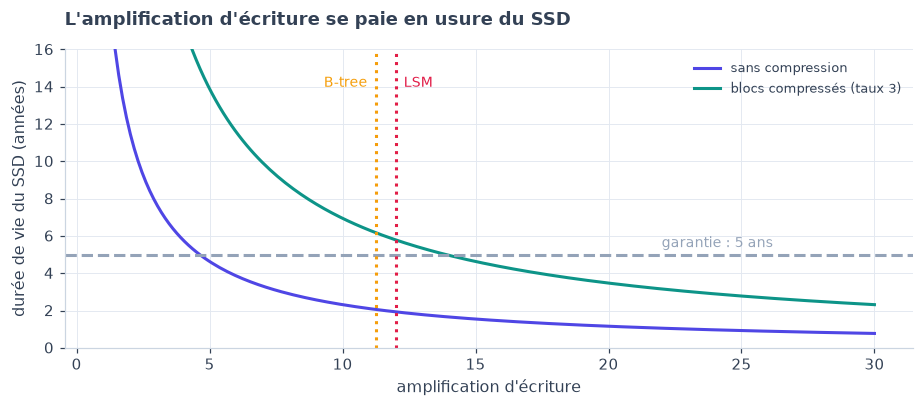

In [3]:
wa = np.linspace(1, 30, 200)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(wa, 7300 / (utile * wa * 86_400 / 1e12) / 365, color=INDIGO, label="sans compression")
ax.plot(wa, 7300 / (utile * wa / 3 * 86_400 / 1e12) / 365, color=TEAL, label="blocs compressés (taux 3)")
ax.axhline(5, color=GRAY, ls="--"); ax.text(22, 5.4, "garantie : 5 ans", color=GRAY, fontsize=9)
for nom, w in [("B-tree", wa_bt), ("LSM", 12)]:
    ax.axvline(w, color=ROSE if nom == "LSM" else AMBER, ls=":")
    if nom == "LSM":
        ax.text(w + 0.3, 14, nom, color=ROSE, fontsize=9)
    else:
        ax.text(w - 0.3, 14, nom, color=AMBER, fontsize=9, ha="right")
ax.set_ylim(0, 16)
ax.set_xlabel("amplification d'écriture"); ax.set_ylabel("durée de vie du SSD (années)")
ax.set_title("L'amplification d'écriture se paie en usure du SSD")
ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

> **À retenir.** Pour dimensionner, on multiplie le débit utile par l'amplification
> d'écriture : on obtient la bande passante consommée et l'usure du SSD. Compression et
> choix de la compaction pèsent autant que la famille de moteur.